## **What factors influence Airbnb nightly prices in Singapore, and where and what type of listing should a new host choose to maximise potential revenue?**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")



In [2]:
df_raw = pd.read_csv("airbnb_singapore.csv")
df_raw.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,71609.0,https://www.airbnb.com/rooms/71609,2.026090e+13,26-09-2026,previous scrape,Ensuite Room (Room 1 & 2) near EXPO,For 3 rooms.Book room 1&2 and room 4,NaN,https://a0.muscache.com/pictures/24453191/3580...,367042.0,...,4.78,4.26,4.32,NaN,NaN,5,0,5,0,0.11
1,71896.0,https://www.airbnb.com/rooms/71896,2.026090e+13,26-09-2026,previous scrape,B&B Room 1 near Airport & EXPO,<b>The space</b><br />Vocational Stay Deluxe B...,NaN,https://a0.muscache.com/pictures/2440674/ac4f4...,367042.0,...,4.43,4.17,4.04,NaN,NaN,5,0,5,0,0.13
2,71903.0,https://www.airbnb.com/rooms/71903,2.026090e+13,26-09-2026,previous scrape,Room 2-near Airport & EXPO,"Like your own home, 24hrs access.",NaN,https://a0.muscache.com/pictures/568743/7bc623...,367042.0,...,4.64,4.50,4.36,NaN,NaN,5,0,5,0,0.25
3,294281.0,https://www.airbnb.com/rooms/294281,2.026090e+13,26-09-2026,previous scrape,5 mins walk from Newton subway,I have 3 bedrooms in a charming British style...,NaN,https://a0.muscache.com/pictures/4607862/87f42...,1521514.0,...,4.66,4.52,4.39,NaN,NaN,7,1,6,0,0.73
4,344803.0,https://www.airbnb.com/rooms/344803,2.026090e+13,26-09-2026,previous scrape,Budget short stay room near EXPO,Direct bus 24 from airport to this place.Walki...,NaN,https://a0.muscache.com/pictures/4240c88e-4dc2...,367042.0,...,4.58,4.66,4.44,NaN,NaN,5,0,5,0,0.34


In [3]:

print("Shape:", df_raw.shape)

Shape: (3208, 90)


In [4]:
df_raw.dtypes

id                                              float64
listing_url                                         str
scrape_id                                       float64
last_scraped                                        str
source                                              str
                                                 ...   
calculated_host_listings_count                    int64
calculated_host_listings_count_entire_homes       int64
calculated_host_listings_count_private_rooms      int64
calculated_host_listings_count_shared_rooms       int64
reviews_per_month                               float64
Length: 90, dtype: object

In [42]:
#Columns needed for analysis
columns= ["listing_url", "price", "room_type", "neighbourhood_group_cleansed",
                   "neighbourhood_cleansed", "accommodates", "bedrooms", "beds",
                   "minimum_nights", "availability_365", "number_of_reviews",
                   "review_scores_rating", "host_is_superhost", "estimated_revenue_l365d"]
df_raw[columns].dtypes

listing_url                         str
price                               str
room_type                           str
neighbourhood_group_cleansed        str
neighbourhood_cleansed              str
accommodates                      int64
bedrooms                        float64
beds                            float64
minimum_nights                  float64
availability_365                  int64
number_of_reviews                 int64
review_scores_rating            float64
host_is_superhost                   str
estimated_revenue_l365d         float64
dtype: object

In [43]:
df_raw[columns].dtypes.value_counts()

str        6
float64    5
int64      3
Name: count, dtype: int64

In [44]:
df_raw[columns].describe()

,accommodates,bedrooms,beds,minimum_nights,availability_365,number_of_reviews,review_scores_rating,estimated_revenue_l365d
count,3208.000000,3206.000000,3054.000000,3011.000000,3208.000000,3208.000000,1839.000000,2728.000000
mean,2.776496,1.206176,1.683039,50.194952,263.796135,14.339152,4.539369,4892.238270
std,1.791149,0.761540,1.647158,54.318920,129.552207,55.448409,0.606609,13335.555001
min,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,2.000000,1.000000,1.000000,1.000000,180.000000,0.000000,4.330000,0.000000
50%,2.000000,1.000000,1.000000,22.000000,338.500000,1.000000,4.730000,0.000000
75%,4.000000,1.000000,2.000000,92.000000,360.000000,8.000000,5.000000,2759.500000
max,16.000000,10.000000,50.000000,730.000000,365.000000,1519.000000,5.000000,206346.000000


## Data Cleaning

In [45]:
df = df_raw.dropna(axis=1, how="all")
print("Columns before:", df_raw.shape[1])
print("Columns after: ", df.shape[1])

Columns before: 90
Columns after:  77


In [50]:
df = df[columns].copy()
print(df)
print("Shape", df.shape)

                                           listing_url    price  \
0                   https://www.airbnb.com/rooms/71609      NaN   
1                   https://www.airbnb.com/rooms/71896      NaN   
2                   https://www.airbnb.com/rooms/71903      NaN   
3                  https://www.airbnb.com/rooms/294281   $86.63   
4                  https://www.airbnb.com/rooms/344803   $44.26   
...                                                ...      ...   
3203  https://www.airbnb.com/rooms/1772377028543433386  $124.64   
3204  https://www.airbnb.com/rooms/1775264196565419940  $163.47   
3205  https://www.airbnb.com/rooms/1775265152149162419  $291.91   
3206  https://www.airbnb.com/rooms/1775266127973353754  $350.00   
3207  https://www.airbnb.com/rooms/1776729921357236629  $880.00   

            room_type neighbourhood_group_cleansed neighbourhood_cleansed  \
0        Private room                  East Region               Tampines   
1        Private room                  Ea

In [51]:
# Fixing datatypes

#price(removing $ sign) 
df["price"] = df["price"].str.replace("$", "", regex=False)
df["price"] = df["price"].str.replace(",", "", regex=False)
df["price"] = df["price"].astype(float)

#Superhost( "t" and "f" are converted to True and False)
df["host_is_superhost"] = df["host_is_superhost"].map({"t": True, "f": False})
df[["price", "host_is_superhost"]].dtypes

price                float64
host_is_superhost       bool
dtype: object

In [52]:
#Checking duplicates
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate listing links:", df["listing_url"].duplicated().sum())

Duplicate rows: 0
Duplicate listing links: 0


In [53]:
#Handling Missing Values
df.isna().sum()

listing_url                        0
price                            480
room_type                          0
neighbourhood_group_cleansed       0
neighbourhood_cleansed             0
accommodates                       0
bedrooms                           2
beds                             154
minimum_nights                   197
availability_365                   0
number_of_reviews                  0
review_scores_rating            1369
host_is_superhost                  0
estimated_revenue_l365d          480
dtype: int64

In [58]:
rows_before = len(df)
df = df.dropna(subset=["price"])
df["bedrooms"] = df["bedrooms"].fillna(df["bedrooms"].median())
df["beds"] = df["beds"].fillna(df["beds"].median())
df["minimum_nights"] = df["minimum_nights"].fillna(df["minimum_nights"].median())
print(df.isna().sum())


listing_url                        0
price                              0
room_type                          0
neighbourhood_group_cleansed       0
neighbourhood_cleansed             0
accommodates                       0
bedrooms                           0
beds                               0
minimum_nights                     0
availability_365                   0
number_of_reviews                  0
review_scores_rating            1156
host_is_superhost                  0
estimated_revenue_l365d            0
dtype: int64


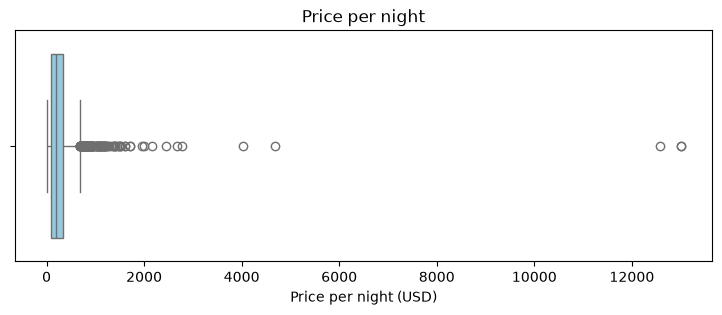

In [60]:
#Handling outliers
plt.figure(figsize=(9, 3))
sns.boxplot(x=df["price"], color="skyblue")
plt.title("Price per night")
plt.xlabel("Price per night (USD)")
plt.show()

In [61]:
print(df["price"].describe().round(2))
print()
print("99th percentile of price:", round(df["price"].quantile(0.99), 2))
print("Listings under $10 a night:", (df["price"] < 10).sum())
print("Highest minimum stay left in the data:", df["minimum_nights"].max(), "nights")

count     2728.00
mean       277.33
std        494.48
min          0.22
25%         99.95
50%        202.77
75%        333.08
max      13000.00
Name: price, dtype: float64

99th percentile of price: 1244.9
Listings under $10 a night: 1
Highest minimum stay left in the data: 365.0 nights


In [64]:
rows_before = len(df)

price_limit = df["price"].quantile(0.99)
df = df[df["price"] <= price_limit]
df = df[df["price"] >= 10]

df = df.reset_index(drop=True) 
print("Rows removed:", rows_before - len(df))
print("Rows left:", len(df))

print(df.shape)
print(df.info())

Rows removed: 27
Rows left: 2645
(2645, 14)
<class 'pandas.DataFrame'>
RangeIndex: 2645 entries, 0 to 2644
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   listing_url                   2645 non-null   str    
 1   price                         2645 non-null   float64
 2   room_type                     2645 non-null   str    
 3   neighbourhood_group_cleansed  2645 non-null   str    
 4   neighbourhood_cleansed        2645 non-null   str    
 5   accommodates                  2645 non-null   int64  
 6   bedrooms                      2645 non-null   float64
 7   beds                          2645 non-null   float64
 8   minimum_nights                2645 non-null   float64
 9   availability_365              2645 non-null   int64  
 10  number_of_reviews             2645 non-null   int64  
 11  review_scores_rating          1535 non-null   float64
 12  host_is_superhost            

## EDA

#### Distributions


In [70]:
df[["price", "accommodates", "bedrooms", "review_scores_rating",
    "number_of_reviews", "availability_365"]].describe().round(2)

,price,accommodates,bedrooms,review_scores_rating,number_of_reviews,availability_365
count,2645.00,2645.00,2645.00,1535.00,2645.00,2645.00
mean,233.00,2.76,1.15,4.53,15.05,286.12
std,166.70,1.74,0.67,0.61,59.50,110.73
min,19.69,1.00,0.00,1.00,0.00,0.00
25%,98.12,2.00,1.00,4.33,0.00,261.00
50%,196.64,2.00,1.00,4.71,1.00,345.00
75%,314.10,4.00,1.00,5.00,8.00,361.00
max,827.50,16.00,7.00,5.00,1519.00,365.00


In [68]:
print("Average price:", round(df["price"].mean(), 2))
print("Median price:", round(df["price"].median(), 2))
print("Skewness:", round(df["price"].skew(), 2))

Average price: 233.0
Median price: 196.64
Skewness: 1.09


#### Groupby

In [28]:
# Price by room type
room = df.groupby("room_type")["price"].agg(["count", "mean", "median"]).round(2).sort_values("median", ascending=False)
room

,count,mean,median
room_type,,,
Entire home/apt,1059,356.70,300.00
Hotel room,73,240.69,188.00
Private room,1506,180.22,126.36
Shared room,61,59.95,52.00


In [72]:
# Price by region
region=df.groupby("neighbourhood_group_cleansed")["price"].agg(["count", "mean", "median"]).round(2).sort_values("median", ascending=False)
region

,count,mean,median
neighbourhood_group_cleansed,,,
Central Region,2256,243.84,212.90
North-East Region,77,188.43,136.00
West Region,137,213.47,118.15
East Region,141,136.46,101.33
North Region,34,94.01,73.25


In [73]:
# Top 10 most expensive neighbourhoods (with at least 20 listings)
neighbourhoods = df.groupby("neighbourhood_cleansed")["price"].agg(["count", "median"])
neighbourhoods = neighbourhoods[neighbourhoods["count"] >= 20]
top10 = neighbourhoods.sort_values("median", ascending=False).head(10)
top10

,count,median
neighbourhood_cleansed,,
Orchard,73,395.000
Clementi,50,305.190
Jurong East,25,301.570
Singapore River,133,285.600
River Valley,433,283.450
Novena,159,279.230
Tanglin,29,270.000
Queenstown,129,259.000
Downtown Core,146,230.000


In [74]:
# Superhost vs normal host
df.groupby("host_is_superhost")[["price", "review_scores_rating", "number_of_reviews"]].median().round(2)

,price,review_scores_rating,number_of_reviews
host_is_superhost,,,
False,193.28,4.60,1.0
True,224.00,4.86,6.0


In [76]:
#listings with no revenue
no_revenue = (df["estimated_revenue_l365d"] == 0).mean() * 100
print(f"Listings with zero estimated revenue: {no_revenue:.1f}%")

Listings with zero estimated revenue: 69.0%


In [77]:
#Typical Yearly review per room type
earning = df[df["estimated_revenue_l365d"] > 0]
earning.groupby("room_type")["estimated_revenue_l365d"].median().round(0).sort_values(ascending=False)

room_type
Private room       10719.0
Entire home/apt     8336.0
Hotel room          7506.0
Shared room         2106.0
Name: estimated_revenue_l365d, dtype: float64

### Correlation

In [78]:
#columns with price
number_columns = ["price", "accommodates", "bedrooms", "beds", "minimum_nights",
                  "availability_365", "number_of_reviews", "review_scores_rating",
                  "estimated_revenue_l365d"]
corr = df[number_columns].corr()
corr["price"].drop("price").sort_values(ascending=False).round(2)

accommodates               0.49
bedrooms                   0.28
beds                       0.13
estimated_revenue_l365d    0.10
review_scores_rating       0.08
availability_365           0.03
number_of_reviews         -0.10
minimum_nights            -0.37
Name: price, dtype: float64

## Visualization

####  1.Distribution of Price

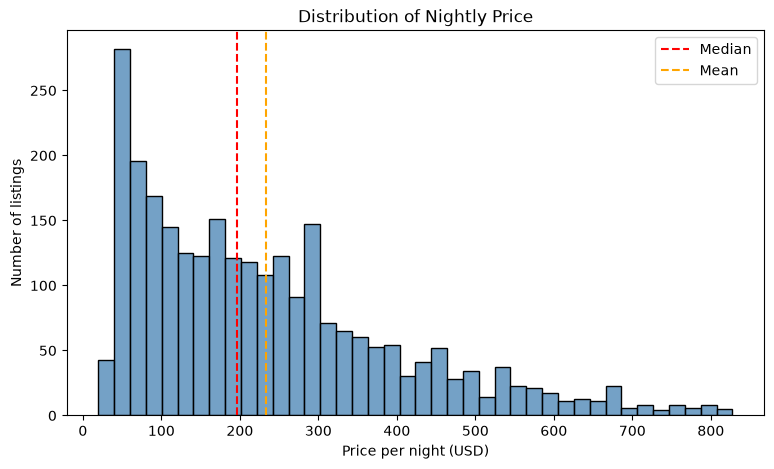

In [79]:

plt.figure(figsize=(9, 5))
sns.histplot(df["price"], bins=40, color="steelblue")
plt.axvline(df["price"].median(), color="red", linestyle="--", label="Median")
plt.axvline(df["price"].mean(), color="orange", linestyle="--", label="Mean")
plt.title("Distribution of Nightly Price")
plt.xlabel("Price per night (USD)")
plt.ylabel("Number of listings")
plt.legend()
plt.show()

#### 2.Price by room type

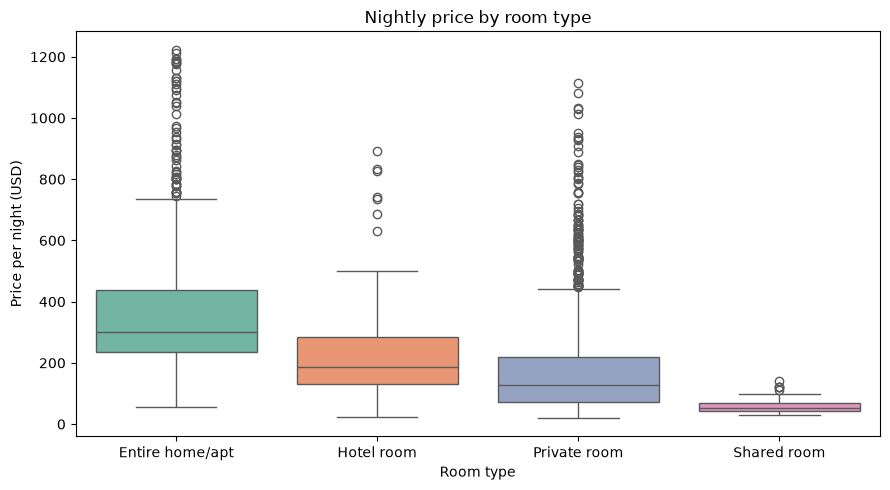

In [36]:
order = df.groupby("room_type")["price"].median().sort_values(ascending=False).index
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="room_type", y="price", order=order, palette="Set2")
plt.title("Nightly price by room type")
plt.xlabel("Room type")
plt.ylabel("Price per night (USD)")
plt.tight_layout()
plt.show()

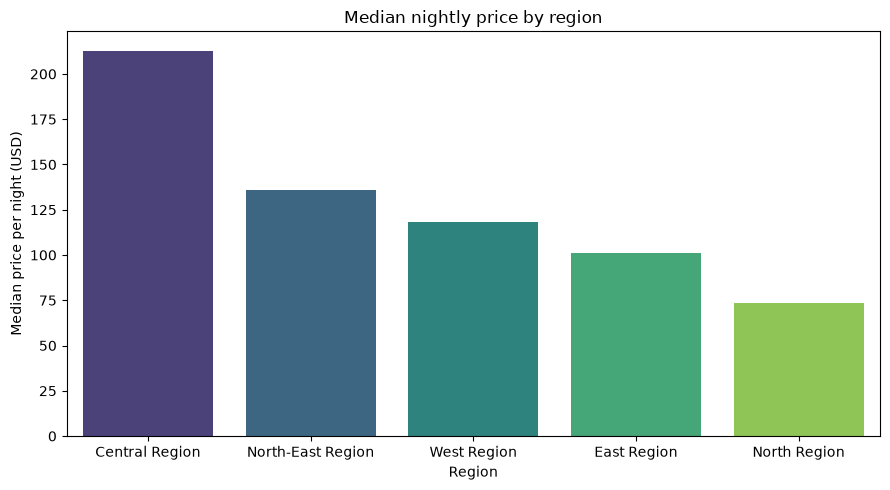

In [81]:
region_price = df.groupby("neighbourhood_group_cleansed")["price"].median().sort_values(ascending=False).reset_index()
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=region_price, x="neighbourhood_group_cleansed", y="price", palette="viridis")
plt.title("Median nightly price by region")
plt.xlabel("Region")
plt.ylabel("Median price per night (USD)")
plt.tight_layout()
plt.show()

#### 4.Top 10 most expensive neighbourhoods


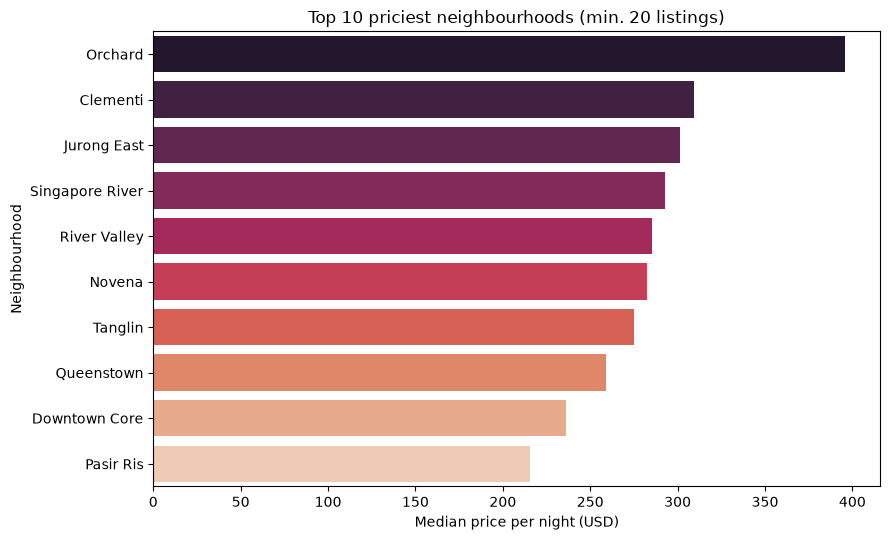

In [82]:

plt.figure(figsize=(9, 5.5))
sns.barplot(data=top, y="neighbourhood_cleansed", x="median", palette="rocket")
plt.title("Top 10 priciest neighbourhoods (min. 20 listings)")
plt.xlabel("Median price per night (USD)")
plt.ylabel("Neighbourhood")
plt.tight_layout()
plt.show()


#### 5. Correlation heatmap

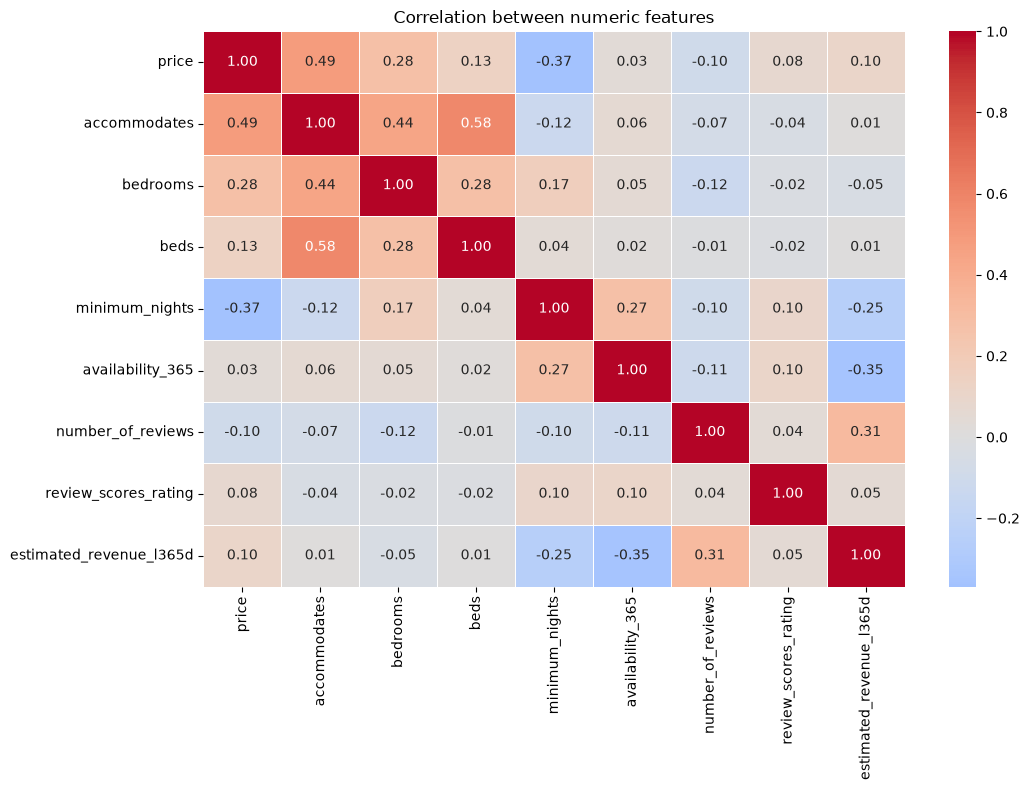

In [83]:
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation between numeric features")
plt.tight_layout()
plt.show()

#### 6. Guests accommodated vs price

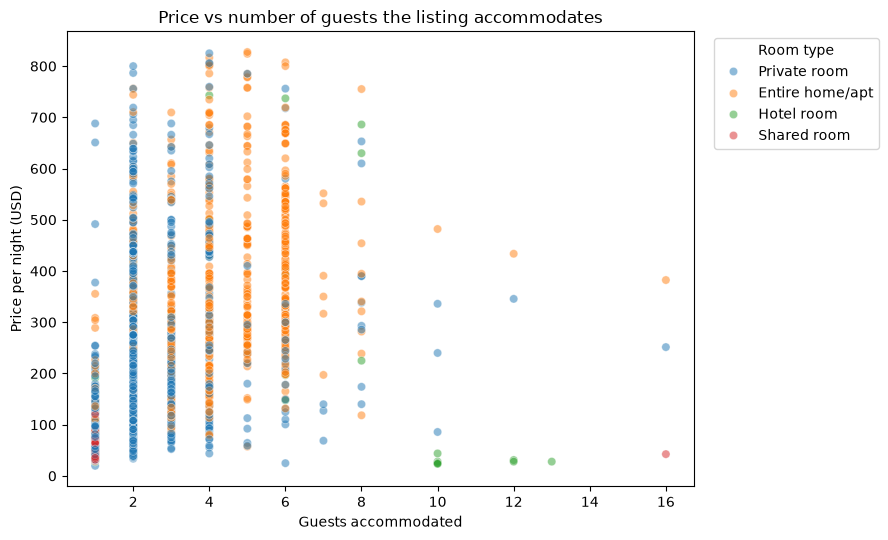

In [84]:
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=df, x="accommodates", y="price", hue="room_type", alpha=0.5)
plt.title("Price vs number of guests the listing accommodates")
plt.xlabel("Guests accommodated")
plt.ylabel("Price per night (USD)")
plt.legend(title="Room type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

#### 7 .Airbnb listings across Singapore

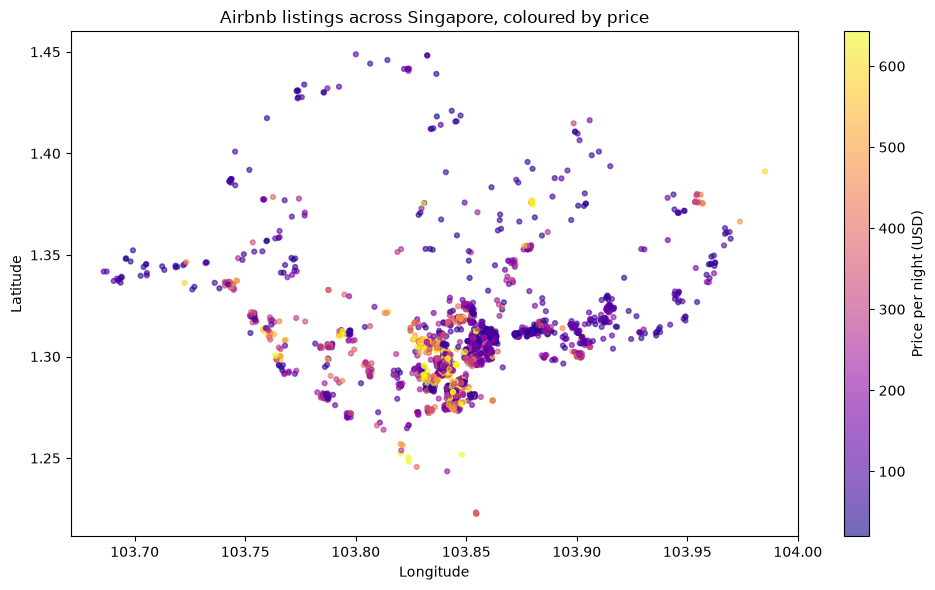

In [41]:
plt.figure(figsize=(10, 6))
sc = plt.scatter(df["longitude"], df["latitude"], c=df["price"], cmap="plasma",
                 s=12, alpha=0.6, vmax=df["price"].quantile(0.95))
plt.colorbar(sc, label="Price per night (USD)")
plt.title("Airbnb listings across Singapore, coloured by price")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

### Key Insights

1.**Singapore Airbnb is almost entirely a Central Region story.** About 83% of the cleaned listings (2,256 of 2,699) are in the Central Region, and it also has the highest median price (~$213 a night). The North Region is the cheapest  at ~$73, with only 34 listings.

2.**Room type is the biggest price divider.** The median entire home costs about $300 a night, against ~$188 for a hotel room, ~$126 for a private room and ~$52 for a shared room. An entire home costs roughly 2.4 times a private room.

3.**Price is right-skewed.** The mean ($233) sits well above the median ($196), and the skewness is 1.09. A small group of luxury listings pulls the average up, which is why the median is the fairer number to quote.

4.**Long minimum stays come with cheaper nights.** minimum_nights has a negative correlation with price (-0.37), so hosts who only accept longer stays tend to charge less per night.

5.**Orchard is the priciest area** Orchard leads at about $395 median, followed by Clementi and Jurong East (both near $300). Those two have fewer listings (25 to 50), so treat them with some caution.

6.**Most listings are not earning.** About 69% have zero estimated revenue over the last 12 months, and the median listing is open for booking about 345 days a year. Among listings that did earn, private rooms had the highest median revenue (~$10,700), ahead of entire homes (~$8,600), even though they charge less per night.

### Conclusion

Nightly price in Singapore is driven mainly by **what you are renting and how big it is**: entire homes and places that sleep more guests cost much more, and location matters too, with Orchard and the Central Region at the top. Reviews and Superhost status are linked to trust and bookings rather than to price. For a new host, the data suggests a well-located private room or small home in the Central Region is a sensible start, since private rooms earned the most among active listings, but they should expect heavy competition from professional hosts.
